# Value at Risk (VaR) - Multi-Asset Portfolio: Historical vs. Variance-Covariance (Parametric)

## Portfolio Risk Approach

For a multi-asset portfolio, portfolio returns are calculated using asset returns and portfolio weights:

$$
R_p=\sum_{i=1}^{m}w_iR_i=w^TR
$$

Where $w_i$ is the weight of asset $i$, $R_i$ is its return, and $m$ is the number of assets.

### 1. Historical Simulation

Apply the historical method to the portfolio return series.

**Value at Risk (VaR):**

$$
\operatorname{VaR}_{\alpha}^{\text{Hist}}
=-Q_{1-\alpha}(R_p)
$$

**Expected Shortfall (ES):**

$$
\operatorname{ES}_{\alpha}^{\text{Hist}}
=-\mathbb{E}\left[R_p\mid R_p\leq Q_{1-\alpha}(R_p)\right]
$$

Here, $Q_{1-\alpha}(R_p)$ is the empirical lower-tail quantile of historical portfolio returns.

### 2. Variance-Covariance (Parametric)

**Portfolio Moments:**

$$
\mu_p=w^T\mu=\sum_{i=1}^{m}w_i\mu_i
$$

$$
\sigma_p^2=w^T\Sigma w
$$

$$
\sigma_p=\sqrt{w^T\Sigma w}
$$

**VaR and ES (Assuming Multivariate Normal Returns):**

**Value at Risk (VaR):**

$$
\operatorname{VaR}_{\alpha,p}^{\text{Param}}
=z_{\alpha}\sigma_p-\mu_p
$$

**Expected Shortfall (ES):**

$$
\operatorname{ES}_{\alpha,p}^{\text{Param}}
=-\mu_p+\frac{\sigma_p\phi(z_{\alpha})}{1-\alpha}
$$

**Where:**

- $\mu_p$ = Expected portfolio return.
- $\sigma_p$ = Portfolio standard deviation.
- $w$ = Portfolio weight vector.
- $\Sigma$ = Covariance matrix of asset returns.
- $z_{\alpha}=\Phi^{-1}(\alpha)$ = Standard normal quantile.
- $\phi(z_{\alpha})$ = Standard normal probability density function (PDF) evaluated at $z_{\alpha}$.

The covariance matrix $\Sigma$ captures both individual asset volatilities and correlations between assets.

[*********************100%***********************]  4 of 4 completed



=== Portfolio Risk Summary (AAPL, MSFT, GOOGL, AMZN) ===
Allocation Weights:   {'AAPL': np.float64(0.4), 'MSFT': np.float64(0.3), 'GOOGL': np.float64(0.15), 'AMZN': np.float64(0.15)}
Historical VaR (95%): 2.09%
Historical ES (95%):  3.07%
--------------------------------------------------
Parametric VaR (95%): 2.16%
Parametric ES (95%):  2.73%


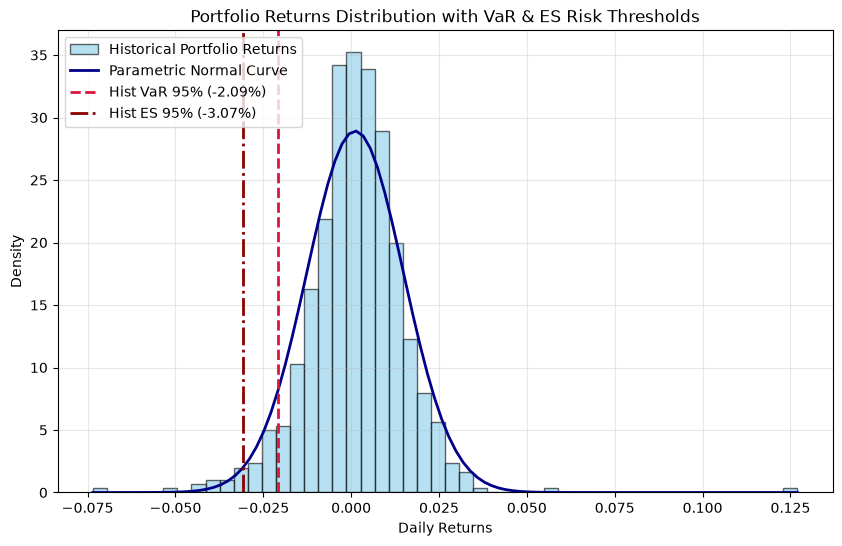

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf
from scipy.stats import norm

# 1. Download multi-asset data from Yahoo Finance
tickers = ["AAPL", "MSFT", "GOOGL", "AMZN"]
start_date = "2023-01-01"
end_date = "2026-01-01"

print(f"Downloading historical data for {tickers}...")

raw_data = yf.download(tickers, period= "3y", auto_adjust=True)

# 2. Extract Adjusted Close and drop multi-index issues if any
adj_close = raw_data["Close"]

# 3. Calculate daily percentage returns
returns = adj_close.pct_change().dropna()

# 4. Define portfolio parameters
weights = np.array([0.40, 0.30, 0.15, 0.15])  # Must sum to 1.0
confidence_level = 0.95
holding_period = 1  # 1-day horizon

# Compute the aggregate daily portfolio returns
portfolio_returns = returns.dot(weights)
portfolio_returns_arr = portfolio_returns.to_numpy().flatten()


# RISK METRICS CALCULATIONS


#  Method 1: Historical Simulation 
portfolio_var_hist = -np.percentile(
    portfolio_returns_arr, (1 - confidence_level) * 100
)
tail_losses_hist = portfolio_returns_arr[
    portfolio_returns_arr <= -portfolio_var_hist
]
portfolio_es_hist = -np.mean(tail_losses_hist)

#  Method 2: Parametric (Variance-Covariance Matrix) 
# Portfolio Expected Return: E(R_p) = W^T * Mean(R)
mean_returns = returns.mean()
portfolio_mean = np.dot(weights, mean_returns)

# Portfolio Variance: Var(R_p) = W^T * Cov(R) * W
cov_matrix = returns.cov()  # Empirical covariance matrix
portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
portfolio_std_dev = np.sqrt(portfolio_variance)

# Parametric Risk Metrics
z_score = norm.ppf(confidence_level)
portfolio_var_param = -(portfolio_mean - z_score * portfolio_std_dev)

alpha = 1 - confidence_level
portfolio_es_param = -(
    portfolio_mean
    - portfolio_std_dev * (norm.pdf(norm.ppf(alpha)) / alpha)
)


# PRINT RESULTS

print(f"\n=== Portfolio Risk Summary ({', '.join(tickers)}) ===")
print(f"Allocation Weights:   {dict(zip(tickers, weights))}")
print(f"Historical VaR (95%): {portfolio_var_hist * 100:.2f}%")
print(f"Historical ES (95%):  {portfolio_es_hist * 100:.2f}%")
print("-" * 50)
print(f"Parametric VaR (95%): {portfolio_var_param * 100:.2f}%")
print(f"Parametric ES (95%):  {portfolio_es_param * 100:.2f}%")


# PLOT THE RETURNS DISTRIBUTION

plt.figure(figsize=(10, 6))

# Plot historical returns histogram
plt.hist(
    portfolio_returns_arr,
    bins=50,
    alpha=0.6,
    color="skyblue",
    edgecolor="black",
    density=True,
    label="Historical Portfolio Returns",
)

# Plot Parametric Normal Fit for context
x_axis = np.linspace(
    portfolio_returns_arr.min(), portfolio_returns_arr.max(), 100
)
plt.plot(
    x_axis,
    norm.pdf(x_axis, portfolio_mean, portfolio_std_dev),
    color="darkblue",
    linewidth=2,
    label="Parametric Normal Curve",
)

# Add visual markers for VaR and ES thresholds (multiplied by -1 to align with returns scale)
plt.axvline(
    -portfolio_var_hist,
    color="crimson",
    linestyle="dashed",
    linewidth=2,
    label=f"Hist VaR 95% ({-portfolio_var_hist*100:.2f}%)",
)
plt.axvline(
    -portfolio_es_hist,
    color="darkred",
    linestyle="dashdot",
    linewidth=2,
    label=f"Hist ES 95% ({-portfolio_es_hist*100:.2f}%)",
)

plt.title("Portfolio Returns Distribution with VaR & ES Risk Thresholds")
plt.xlabel("Daily Returns")
plt.ylabel("Density")
plt.legend(loc="upper left")
plt.grid(alpha=0.3)
plt.show()
